# Calibration

## Importing packages

In [20]:
# Data handling and manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Statistical modeling and optimization
import statsmodels.api as sm
import optbinning as optb
from scipy.stats import chi2, binom

# Progress bar utility
from tqdm import tqdm

# Metrics
from sklearn.metrics import roc_auc_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Serialization and deserialization
import pickle

## Loading data

In [21]:
cali_data = pd.read_csv("Data/pd_modelling.csv")

## Loading model

In [22]:
with open("Pickle/binning_var.pkl", "rb") as f:
    binning = pickle.load(f)

In [23]:
with open("Pickle/model.pkl", "rb") as f:
    model = pickle.load(f)

## Calculating PD and WoE values

In [24]:
woe = []

for var in binning.keys():
    woe.append(pd.Series(binning[var].transform(cali_data[var], metric = "woe"), index=cali_data.index, name="WoE_" + var))

cali_data_woe = pd.concat([cali_data] + woe, axis=1)

In [25]:
vars = model.model.exog_names
cali_data_woe["const"] = 1

cali_data_woe["uncalibrated_pd"] = model.predict(cali_data_woe[vars])

C:\Users\niels\AppData\Local\Temp\ipykernel_8992\515790858.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  cali_data_woe["const"] = 1
C:\Users\niels\AppData\Local\Temp\ipykernel_8992\515790858.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  cali_data_woe["uncalibrated_pd"] = model.predict(cali_data_woe[vars])


## Calculating LRA DR

In [38]:
dr = cali_data_woe.groupby("quarter")[["default_12m", "uncalibrated_pd"]].mean()

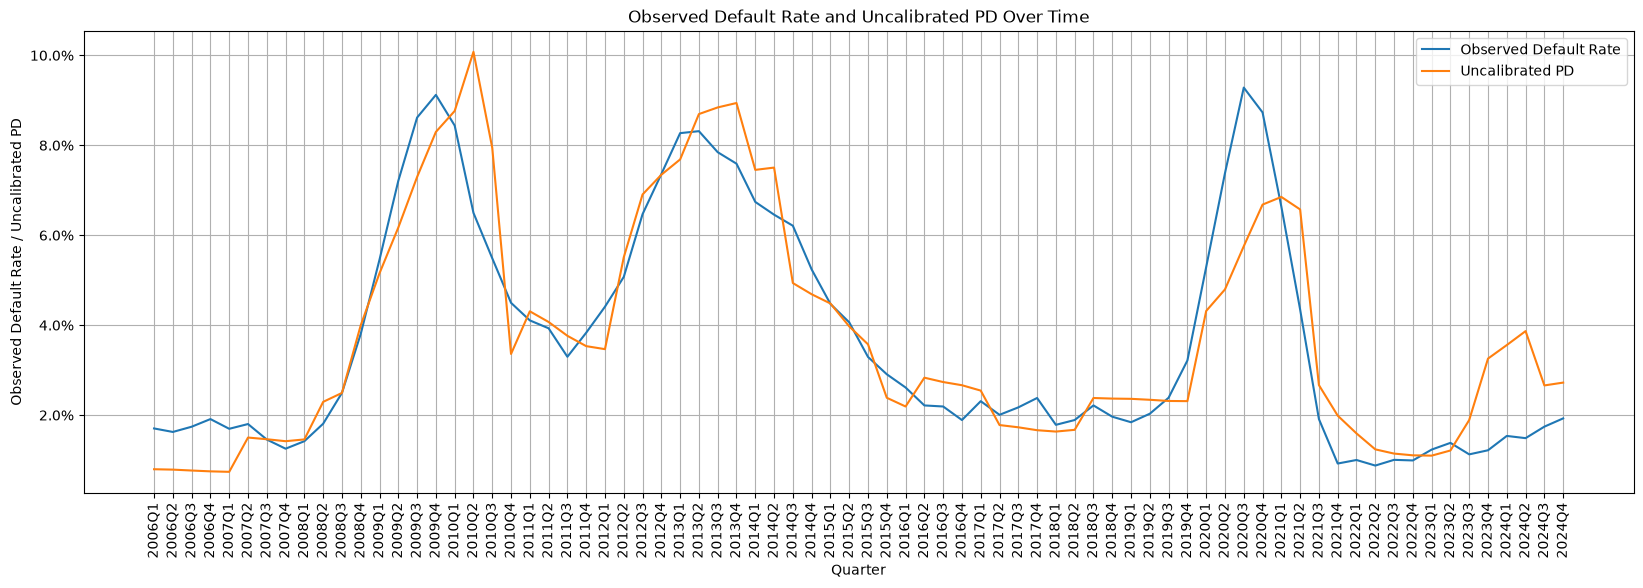

In [40]:
plt.figure(figsize=(20, 6))
plt.plot(dr.index, dr["default_12m"], label="Observed Default Rate")
plt.plot(dr.index, dr["uncalibrated_pd"], label="Uncalibrated PD")
plt.xlabel("Quarter")
plt.ylabel("Observed Default Rate / Uncalibrated PD")
plt.title("Observed Default Rate and Uncalibrated PD Over Time")
plt.xticks(rotation=90)
plt.grid(True)
plt.legend(loc = 'best')
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax = 1, decimals = 1))
plt.show()

In [41]:
lra_dr = dr["default_12m"].mean()

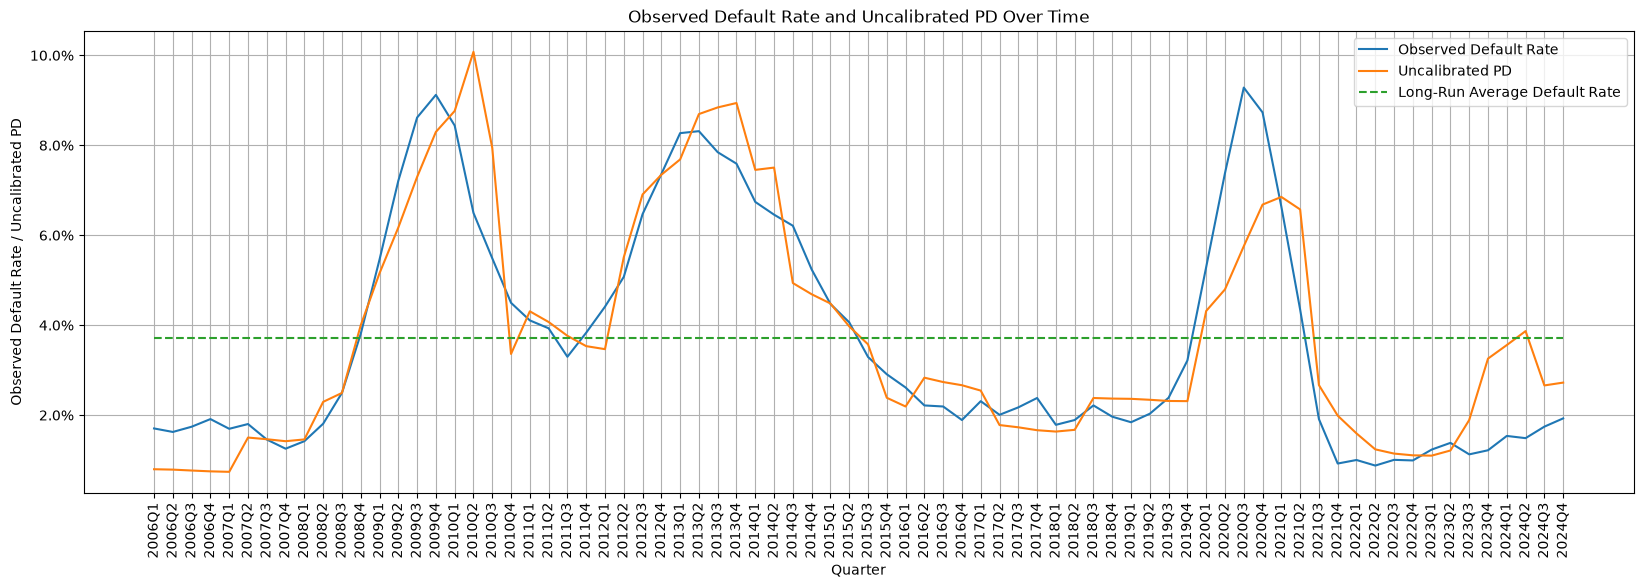

In [42]:
plt.figure(figsize=(20, 6))
plt.plot(dr.index, dr["default_12m"], label="Observed Default Rate")
plt.plot(dr.index, dr["uncalibrated_pd"], label="Uncalibrated PD")
plt.xlabel("Quarter")
plt.ylabel("Observed Default Rate / Uncalibrated PD")
plt.title("Observed Default Rate and Uncalibrated PD Over Time")
plt.xticks(rotation=90)
plt.plot(dr.index, [lra_dr]*len(dr.index), label="Long-Run Average Default Rate", linestyle="--")
plt.grid(True)
plt.legend(loc = 'best')
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax = 1, decimals = 1))
plt.show()

In [ ]:
def adjustment_score(pds, target):
    